<a href="https://colab.research.google.com/github/Jahura7/assignment_on_research_design_and_experiment/blob/experiment/experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Imports and Loading Dataset**

In [185]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [186]:
df = pd.read_csv('stroke_risk_prediction_dataset.csv')

# **Exploratory Data Analysis (EDA)**

**STEP 1: SHAPE & STRUCTURAL INTEGRITY CHECK (EDA)**

In [187]:
print(f"Initial Shape: {df.shape}")

Initial Shape: (50000, 40)


In [188]:
df.head()

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
0,1,80.0,Male,China,145.2,69.3,32.9,112,82,109,...,Excellent,NaN,79.0,Retired,Urban,High,47,Exercise Regularly,Yes,Moderate
1,2,37.0,Female,United Kingdom,188.6,110.8,31.1,137,76,59,...,Average,0.6,48.0,Student,Rural,Medium,40,Improve Diet Quality,Yes,Moderate
2,3,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,...,Poor,1.7,114.0,Private,Rural,Medium,76,Monitor Blood Glucose Daily,Yes,High
3,4,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,...,Poor,1.5,101.0,Retired,Rural,Low,40,Exercise Regularly,Yes,Moderate
4,5,52.0,Female,United States,162.8,103.6,39.1,115,60,70,...,Average,7.1,55.0,Government,Rural,Medium,38,Monitor Blood Pressure,Yes,Moderate


In [189]:
df.tail()

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
49995,49996,22.0,Male,Spain,171.7,113.4,38.5,139,78,81,...,Average,3.2,41.0,Government,Urban,Medium,40,Improve Diet Quality,No,Moderate
49996,49997,61.0,Male,South Africa,164.6,64.0,23.6,123,92,87,...,Poor,0.7,92.0,Student,Rural,Medium,59,Reduce Sodium Intake,Yes,Moderate
49997,49998,76.0,Female,Spain,148.9,56.4,25.4,153,93,95,...,Average,0.7,31.0,Retired,Urban,High,64,Improve Diet Quality,Yes,Moderate
49998,49999,31.0,Other,Italy,183.7,75.7,22.4,108,77,76,...,Poor,3.4,90.0,Retired,Rural,Low,26,Continue Regular Exercise,No,Low
49999,50000,45.0,Male,Italy,165.1,123.3,45.2,169,95,96,...,Average,0.5,74.0,Self-Employed,Urban,Medium,51,Exercise Regularly,No,Moderate


In [190]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Patient_ID                    50000 non-null  int64  
 1   Age                           49781 non-null  float64
 2   Gender                        50000 non-null  object 
 3   Country                       50000 non-null  object 
 4   Height_cm                     48475 non-null  float64
 5   Weight_kg                     48477 non-null  float64
 6   BMI                           50000 non-null  float64
 7   Blood_Pressure_Systolic       50000 non-null  int64  
 8   Blood_Pressure_Diastolic      50000 non-null  int64  
 9   Heart_Rate                    50000 non-null  int64  
 10  Blood_Glucose                 49040 non-null  float64
 11  HbA1c                         48994 non-null  float64
 12  Total_Cholesterol             48996 non-null  float64
 13  H

In [191]:
df.describe()

,Patient_ID,Age,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Blood_Glucose,HbA1c,Total_Cholesterol,HDL,LDL,Triglycerides,Sleep_Hours,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Stroke_Risk_Score
count,50000.000000,49781.000000,48475.000000,48477.000000,50000.000000,50000.000000,50000.000000,50000.000000,49040.000000,48994.000000,48996.000000,48979.000000,48950.000000,48968.000000,48974.000000,48946.000000,48949.000000,50000.000000
mean,25000.500000,53.903096,170.125582,87.506141,30.901386,135.061420,84.840620,82.521020,145.031421,7.488103,225.020832,57.661655,140.149685,205.200147,7.005401,5.001214,59.947742,54.782320
std,14433.901067,21.070953,14.484573,24.565490,10.254560,20.526562,14.685149,16.141082,43.405484,1.733379,54.776297,18.718465,46.146752,83.538912,1.731441,2.892267,34.987073,13.996729
min,1.000000,18.000000,145.000000,45.000000,11.900000,100.000000,60.000000,55.000000,70.000000,4.500000,130.000000,25.000000,60.000000,60.000000,4.000000,0.000000,0.000000,2.000000
25%,12500.750000,36.000000,157.600000,66.200000,22.700000,117.000000,72.000000,68.000000,107.400000,6.000000,177.700000,41.500000,100.100000,133.200000,5.500000,2.500000,30.000000,45.000000
50%,25000.500000,54.000000,170.100000,87.500000,30.100000,135.000000,85.000000,83.000000,145.100000,7.500000,224.900000,57.700000,140.200000,205.300000,7.000000,5.000000,60.000000,54.000000
75%,37500.250000,72.000000,182.800000,108.800000,37.800000,153.000000,98.000000,97.000000,182.700000,9.000000,272.400000,73.800000,180.000000,277.600000,8.500000,7.500000,90.000000,64.000000
max,50000.000000,90.000000,195.000000,130.000000,61.500000,170.000000,110.000000,110.000000,220.000000,10.500000,320.000000,90.000000,220.000000,350.000000,10.000000,10.000000,120.000000,100.000000


In [192]:
print(df.dtypes.value_counts)

<bound method IndexOpsMixin.value_counts of Patient_ID                        int64
Age                             float64
Gender                           object
Country                          object
Height_cm                       float64
Weight_kg                       float64
BMI                             float64
Blood_Pressure_Systolic           int64
Blood_Pressure_Diastolic          int64
Heart_Rate                        int64
Blood_Glucose                   float64
HbA1c                           float64
Total_Cholesterol               float64
HDL                             float64
LDL                             float64
Triglycerides                   float64
Smoking_Status                   object
Alcohol_Consumption              object
Physical_Activity_Level          object
Sleep_Hours                     float64
Stress_Level                     object
Diet_Quality                     object
Family_History_Stroke            object
Family_History_Heart_Disease     obj

In [193]:
print(f"Total Patient Profiles: {df.shape[0]}")

Total Patient Profiles: 50000


In [194]:
print(f"Total Registered Medical Attributes: {df.shape[1]}")

Total Registered Medical Attributes: 40


**STEP 2: TARGET VECTOR & BALANCE ANALYSIS (EDA)**

In [195]:
target_counts = df['Stroke_Risk'].value_counts()
target_counts

,count
Stroke_Risk,
Moderate,34375
High,12112
Low,3513


In [196]:
target_pct = df['Stroke_Risk'].value_counts(normalize=True) * 100
for idx in target_counts.index:
    print(f"Risk Tier '{idx}': {target_counts[idx]} patients ({target_pct[idx]:.2f}%)")

Risk Tier 'Moderate': 34375 patients (68.75%)
Risk Tier 'High': 12112 patients (24.22%)
Risk Tier 'Low': 3513 patients (7.03%)


/tmp/ipykernel_2642/2095969357.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Stroke_Risk', palette='Set2')


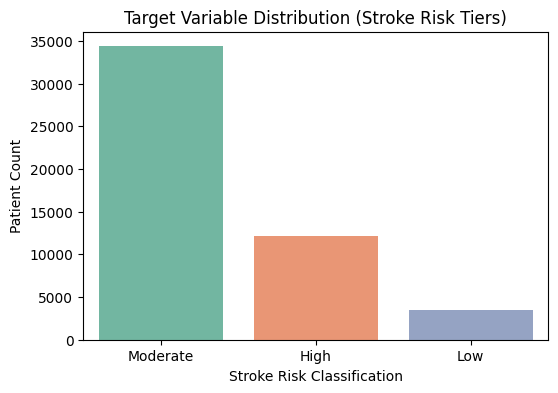

In [197]:
# Visualize target boundary proportions

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Stroke_Risk', palette='Set2')
plt.title('Target Variable Distribution (Stroke Risk Tiers)')
plt.xlabel('Stroke Risk Classification')
plt.ylabel('Patient Count')
plt.show()


**STEP 3: MISSING CLINICAL VALUES PROFILE**

In [198]:
missing_series = df.isnull().sum()
missing_series

,0
Patient_ID,0
Age,219
Gender,0
Country,0
Height_cm,1525
Weight_kg,1523
BMI,0
Blood_Pressure_Systolic,0
Blood_Pressure_Diastolic,0
Heart_Rate,0


In [199]:
missing_columns = missing_series[missing_series > 0].sort_values(ascending=False)
if len(missing_columns) > 0:
    print("Columns with missing observations:")
    for col, count in missing_columns.items():
        pct = (count / len(df)) * 100
        print(f" - {col}: {count} missing records ({pct:.2f}%)")
else:
    print("✅ No empty or missing cells identified within this dataset slice.")


Columns with missing observations:
 - Height_cm: 1525 missing records (3.05%)
 - Weight_kg: 1523 missing records (3.05%)
 - Exercise_Hours_Per_Week: 1054 missing records (2.11%)
 - Medication_Adherence: 1051 missing records (2.10%)
 - Daily_Walking_Minutes: 1051 missing records (2.10%)
 - LDL: 1050 missing records (2.10%)
 - Triglycerides: 1032 missing records (2.06%)
 - Sleep_Hours: 1026 missing records (2.05%)
 - HDL: 1021 missing records (2.04%)
 - HbA1c: 1006 missing records (2.01%)
 - Total_Cholesterol: 1004 missing records (2.01%)
 - Blood_Glucose: 960 missing records (1.92%)
 - Age: 219 missing records (0.44%)


**STEP 4: STATISTICAL CONTINUA CORE TELEMETRY (EDA)**

In [200]:
# Isolate primary quantitative indicators for cardiovascular threat modeling

key_telemetry = ['Age', 'BMI', 'Blood_Pressure_Systolic', 'Blood_Glucose', 'Stroke_Risk_Score']
print(df[key_telemetry].describe().T)


                           count        mean        std    min    25%    50%  \
Age                      49781.0   53.903096  21.070953   18.0   36.0   54.0   
BMI                      50000.0   30.901386  10.254560   11.9   22.7   30.1   
Blood_Pressure_Systolic  50000.0  135.061420  20.526562  100.0  117.0  135.0   
Blood_Glucose            49040.0  145.031421  43.405484   70.0  107.4  145.1   
Stroke_Risk_Score        50000.0   54.782320  13.996729    2.0   45.0   54.0   

                           75%    max  
Age                       72.0   90.0  
BMI                       37.8   61.5  
Blood_Pressure_Systolic  153.0  170.0  
Blood_Glucose            182.7  220.0  
Stroke_Risk_Score         64.0  100.0  


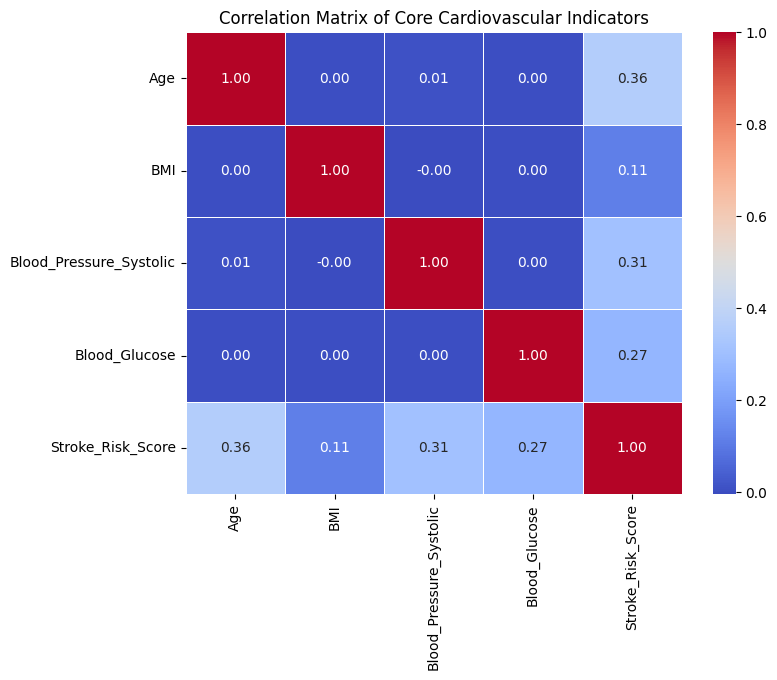

In [201]:
# Subdivided correlation analysis on quantitative metrics

plt.figure(figsize=(8, 6))
sns.heatmap(df[key_telemetry].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Core Cardiovascular Indicators')
plt.show()

**STEP 5: CLINICAL HIGHLIGHTS & OBSERVATIONS (EDA)**

In [202]:
# Unpack basic conditional risk boundaries

mean_glucose_high = df[df['Stroke_Risk'] == 'High']['Blood_Glucose'].mean()
mean_glucose_mod = df[df['Stroke_Risk'] == 'Moderate']['Blood_Glucose'].mean()
print(f"• Mean Blood Glucose for High Risk Cohorts: {mean_glucose_high:.2f} mg/dL")
print(f"• Mean Blood Glucose for Moderate Risk Cohorts: {mean_glucose_mod:.2f} mg/dL")


• Mean Blood Glucose for High Risk Cohorts: 160.00 mg/dL
• Mean Blood Glucose for Moderate Risk Cohorts: 142.14 mg/dL


In [203]:
mean_age_high = df[df['Stroke_Risk'] == 'High']['Age'].mean()
mean_age_mod = df[df['Stroke_Risk'] == 'Moderate']['Age'].mean()
print(f"• Mean Age for High Risk Cohorts: {mean_age_high:.1f} years old")
print(f"• Mean Age for Moderate Risk Cohorts: {mean_age_mod:.1f} years old")

• Mean Age for High Risk Cohorts: 63.4 years old
• Mean Age for Moderate Risk Cohorts: 52.1 years old



# **Data Cleaning and Preprocessing Pipeline**


In [204]:
# 1. Separate target and drop non-predictive clinical keys

target = 'Stroke_Risk'
X = df.drop(columns=['Patient_ID', 'AI_Health_Recommendation', target])
y = df[target]

In [205]:
# Encode Target Column ('Moderate', 'High') -> (0, 1)

from sklearn.preprocessing import LabelEncoder, StandardScaler

target_le = LabelEncoder()
y = target_le.fit_transform(y)

In [206]:
# 2. Identify Numeric and Categorical columns

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

**3**. Handle Missing Values explicitly

In [207]:
from sklearn.impute import SimpleImputer

In [208]:
# Numeric: Impute with median to protect against outliers

num_imputer = SimpleImputer(strategy='median')
X[num_cols] = num_imputer.fit_transform(X[num_cols])

In [209]:
# Categorical: Impute with mode (most frequent)

cat_imputer = SimpleImputer(strategy='most_frequent')
X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])


# **Feature Engineering and Model building**


In [210]:
# Create Pulse Pressure as a risk proxy metric

X['Pulse_Pressure'] = X['Blood_Pressure_Systolic'] - X['Blood_Pressure_Diastolic']


In [211]:
# Create Metabolic Risk Interaction Term

X['Metabolic_Risk_Index'] = X['Blood_Glucose'] * X['BMI']


In [212]:
# Categorical Feature Transformation Encodings

label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le



We will compare:
1. **Baseline: Linear Regression** — used as a requested regression-based baseline. Its continuous predictions are rounded to the nearest encoded class for classification metrics.
2. **Random Forest Classifier** — a classification model that predicts Low, Moderate, and High risk classes directly.

**Important:** `Stroke_Risk_Score` may be closely related to how `Stroke_Risk` is assigned. To reduce possible target leakage, it is excluded from model inputs. We create a fresh stratified train-test split and fit preprocessing only on the training data.

In [213]:
# Prepare predictors and target

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score)

In [214]:
# X has already been imputed and categorical columns encoded in the earlier steps.
# Exclude identifiers, recommendation text, target, and potential leakage feature.

drop_for_model = [c for c in ['Patient_ID', 'AI_Health_Recommendation',
                               'Stroke_Risk', 'Stroke_Risk_Score'] if c in X.columns]

X_model = X.drop(columns=drop_for_model).copy()
y_model = np.asarray(y)

X_train_model, X_test_model, y_train_model, y_test_model = train_test_split(
    X_model, y_model, test_size=0.20, random_state=42, stratify=y_model
)

In [215]:
# Scale for Linear Regression; Random Forest will use the unscaled inputs.

scaler_model = StandardScaler()
X_train_scaled_model = scaler_model.fit_transform(X_train_model)
X_test_scaled_model = scaler_model.transform(X_test_model)

class_names = target_le.classes_
print("Classes:", list(class_names))
print("Training set:", X_train_model.shape)
print("Testing set:", X_test_model.shape)
print("\nTraining class proportions:")
print(pd.Series(target_le.inverse_transform(y_train_model)).value_counts(normalize=True).round(3))


Classes: ['High', 'Low', 'Moderate']
Training set: (40000, 38)
Testing set: (10000, 38)

Training class proportions:
Moderate    0.688
High        0.242
Low         0.070
Name: proportion, dtype: float64


# **Model 1 : Baseline Linear Regression**

In [216]:
# Linear Regression predicts continuous values, not class probabilities.

linear_model = LinearRegression()
linear_model.fit(X_train_scaled_model, y_train_model)


LinearRegression()

In [217]:
linear_pred_continuous = linear_model.predict(X_test_scaled_model)

# Convert predictions to valid encoded class indices for a comparable classification report.
linear_pred_class = np.rint(linear_pred_continuous).astype(int)
linear_pred_class = np.clip(linear_pred_class, 0, len(class_names) - 1)

In [218]:
print("Linear Regression — Classification Report")
print(classification_report(
    y_test_model, linear_pred_class,
    labels=np.arange(len(class_names)), target_names=class_names,
    zero_division=0))

Linear Regression — Classification Report
              precision    recall  f1-score   support

        High       0.99      0.10      0.19      2422
         Low       0.00      0.00      0.00       703
    Moderate       0.84      0.56      0.68      6875

    accuracy                           0.41     10000
   macro avg       0.61      0.22      0.29     10000
weighted avg       0.82      0.41      0.51     10000



In [219]:
print(f"MAE (encoded class values): {mean_absolute_error(y_test_model, linear_pred_continuous):.4f}")
print(f"RMSE (encoded class values): {np.sqrt(mean_squared_error(y_test_model, linear_pred_continuous)):.4f}")
print(f"R² (encoded class values): {r2_score(y_test_model, linear_pred_continuous):.4f}")


MAE (encoded class values): 0.6233
RMSE (encoded class values): 0.7254
R² (encoded class values): 0.2805


# **Model 2: Random Forest Classification**

In [220]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    min_samples_leaf=2,
    n_jobs=-1
)
rf_model.fit(X_train_model, y_train_model)
rf_pred_class = rf_model.predict(X_test_model)


In [221]:
print("Random Forest — Classification Report")
print(classification_report(
    y_test_model, rf_pred_class,
    labels=np.arange(len(class_names)), target_names=class_names,
    zero_division=0
))

Random Forest — Classification Report
              precision    recall  f1-score   support

        High       0.84      0.67      0.74      2422
         Low       0.88      0.57      0.69       703
    Moderate       0.85      0.95      0.90      6875

    accuracy                           0.85     10000
   macro avg       0.86      0.73      0.78     10000
weighted avg       0.85      0.85      0.85     10000



# **Comparative Performance Evaluation**

In [222]:
model_predictions = {
    'Linear Regression (rounded)': linear_pred_class,
    'Random Forest Classifier': rf_pred_class
}

comparison_rows = []
for model_name, pred in model_predictions.items():
    comparison_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test_model, pred),
        'Precision (Macro)': precision_score(y_test_model, pred, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(y_test_model, pred, average='macro', zero_division=0),
        'F1-score (Macro)': f1_score(y_test_model, pred, average='macro', zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_rows).set_index('Model')
display(comparison_df.round(4))

,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
Model,,,,
Linear Regression (rounded),0.4135,0.6096,0.2230,0.2881
Random Forest Classifier,0.8538,0.8601,0.7292,0.7794


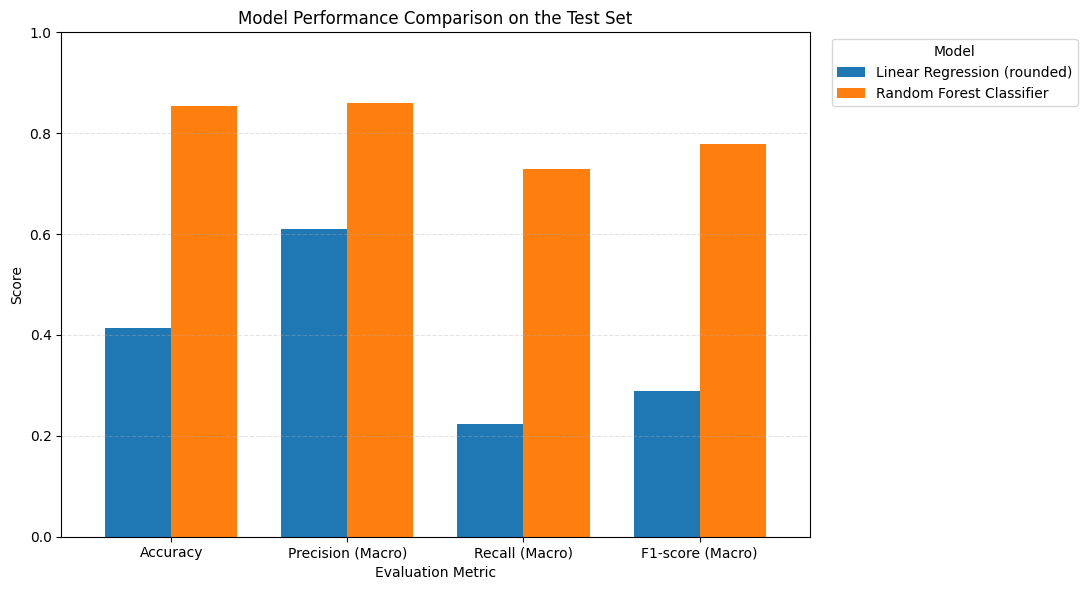

In [223]:
# Visualization 1: Compare key evaluation metrics

metrics_to_plot = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-score (Macro)']
ax = comparison_df[metrics_to_plot].T.plot(kind='bar', figsize=(11, 6), ylim=(0, 1),
                                            rot=0, width=0.75)
ax.set_title('Model Performance Comparison on the Test Set')
ax.set_ylabel('Score')
ax.set_xlabel('Evaluation Metric')
ax.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

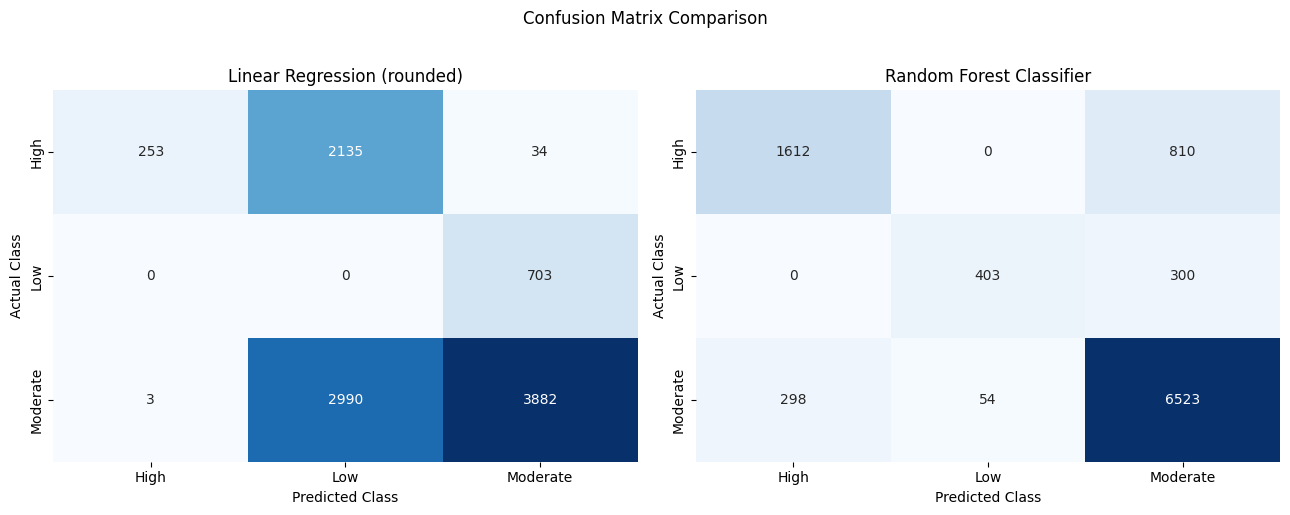

In [224]:
# Visualization 2: Confusion matrices side by side

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (model_name, pred) in zip(axes, model_predictions.items()):
    cm = confusion_matrix(y_test_model, pred, labels=np.arange(len(class_names)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('Actual Class')
plt.suptitle('Confusion Matrix Comparison', y=1.02)
plt.tight_layout()
plt.show()


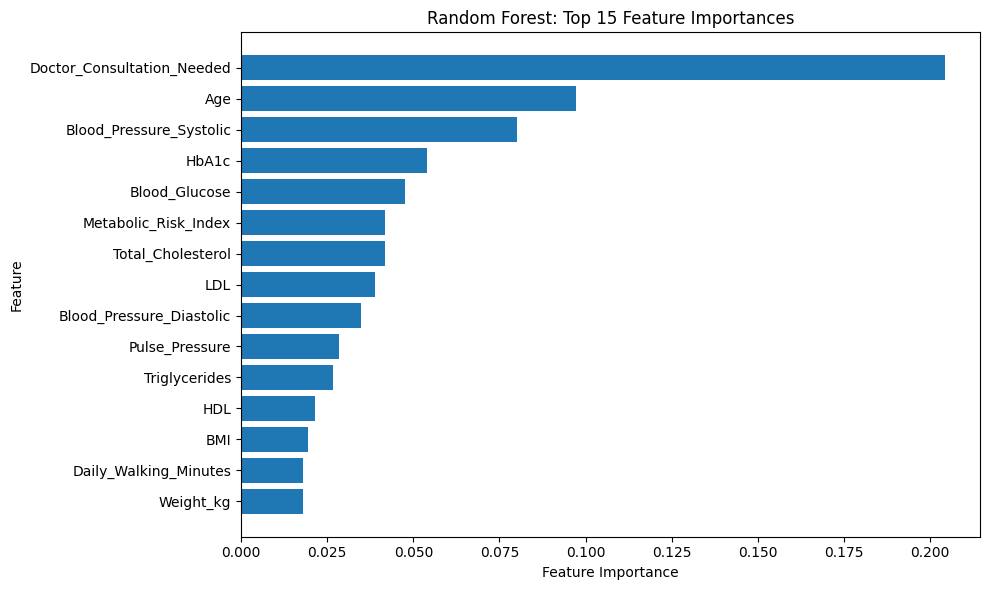

In [225]:
# Visualization 3: Random Forest feature importance (top 15)

feature_importance = pd.Series(
    rf_model.feature_importances_, index=X_train_model.columns
).sort_values(ascending=False).head(15).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(feature_importance.index, feature_importance.values)
plt.title('Random Forest: Top 15 Feature Importances')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [226]:
best_model_by_f1 = comparison_df['F1-score (Macro)'].idxmax()
print("Higher macro F1-score:", best_model_by_f1)
print("\nInterpretation guide:")
print("- Accuracy is the overall proportion of correct predictions.")
print("- Macro precision, recall, and F1 treat Low, Moderate, and High classes equally.")
print("- Check the confusion matrices to see which risk categories are being confused.")
print("- Linear Regression is not designed for classification; treat it as a simple baseline.")
print("- These results measure prediction of the dataset's risk labels, not clinical diagnosis or future stroke occurrence.")

Higher macro F1-score: Random Forest Classifier

Interpretation guide:
- Accuracy is the overall proportion of correct predictions.
- Macro precision, recall, and F1 treat Low, Moderate, and High classes equally.
- Check the confusion matrices to see which risk categories are being confused.
- Linear Regression is not designed for classification; treat it as a simple baseline.
- These results measure prediction of the dataset's risk labels, not clinical diagnosis or future stroke occurrence.
